In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
application_data = pd.read_csv(r'/Users/adityavardhan/Downloads/application_data.csv')
import pandas as pd

# Try specifying a different encoding
columns_description = pd.read_csv(r'/Users/adityavardhan/Downloads/columns_description.csv', encoding='latin1')
previous_application = pd.read_csv(r'/Users/adityavardhan/Downloads/previous_application.csv')

In [25]:
# Check the column names
print(columns_description.columns)


Index(['Unnamed: 0', 'Table', 'Row', 'Description', 'Special'], dtype='object')


In [26]:
# Create a dictionary for column descriptions
column_descriptions = dict(zip(columns_description['Row'], columns_description['Description']))

# Function to get column description
def get_column_description(column_name):
    return column_descriptions.get(column_name, 'No description available')


In [32]:
# Basic structure and sample records for application data
print(application_data.info())
print(application_data.head())

# Previous application data
print(previous_application.info())
print(previous_application.head())

# Check column descriptions structure
print(columns_description.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB
None
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.

In [34]:
# Check missing values
application_missing = application_data.isnull().sum().sort_values(ascending=False)
previous_missing = previous_application.isnull().sum().sort_values(ascending=False)

# Drop columns with high percentage of missing values (optional threshold 50%)
threshold = 0.5
application_data_cleaned = application_data.loc[:, application_data.isnull().mean() < threshold]
previous_application_cleaned = previous_application.loc[:, previous_application.isnull().mean() < threshold]


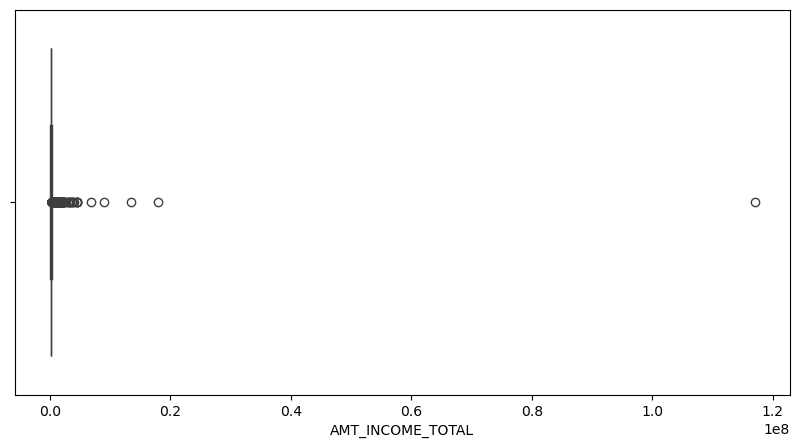

In [36]:
# Remove duplicate records if any
application_data_cleaned = application_data_cleaned.drop_duplicates()
previous_application_cleaned = previous_application_cleaned.drop_duplicates()

# Outlier detection (example for AMT_INCOME_TOTAL)
plt.figure(figsize=(10, 5))
sns.boxplot(data=application_data_cleaned, x='AMT_INCOME_TOTAL')
plt.show()

# Handling outliers by capping at 99th percentile
application_data_cleaned['AMT_INCOME_TOTAL'] = np.where(
    application_data_cleaned['AMT_INCOME_TOTAL'] > application_data_cleaned['AMT_INCOME_TOTAL'].quantile(0.99),
    application_data_cleaned['AMT_INCOME_TOTAL'].quantile(0.99),
    application_data_cleaned['AMT_INCOME_TOTAL']
)


In [38]:
# Create Debt-to-Income Ratio
application_data_cleaned['DEBT_INCOME_RATIO'] = application_data_cleaned['AMT_CREDIT'] / application_data_cleaned['AMT_INCOME_TOTAL']

# Binning Age into groups
application_data_cleaned['AGE_GROUP'] = pd.cut(application_data_cleaned['DAYS_BIRTH'] / -365, 
                                                bins=[20, 30, 40, 50, 60, 100], 
                                                labels=['20s', '30s', '40s', '50s', '60+'])


In [40]:
# Application data statistics
print(application_data_cleaned.describe())

# Previous application statistics
print(previous_application_cleaned.describe())


          SK_ID_CURR         TARGET   CNT_CHILDREN  AMT_INCOME_TOTAL  \
count  307511.000000  307511.000000  307511.000000     307511.000000   
mean   278180.518577       0.080729       0.417052     166025.922341   
std    102790.175348       0.272419       0.722121      83063.469251   
min    100002.000000       0.000000       0.000000      25650.000000   
25%    189145.500000       0.000000       0.000000     112500.000000   
50%    278202.000000       0.000000       0.000000     147150.000000   
75%    367142.500000       0.000000       1.000000     202500.000000   
max    456255.000000       1.000000      19.000000     472500.000000   

         AMT_CREDIT    AMT_ANNUITY  AMT_GOODS_PRICE  \
count  3.075110e+05  307499.000000     3.072330e+05   
mean   5.990260e+05   27108.573909     5.383962e+05   
std    4.024908e+05   14493.737315     3.694465e+05   
min    4.500000e+04    1615.500000     4.050000e+04   
25%    2.700000e+05   16524.000000     2.385000e+05   
50%    5.135310e+05  

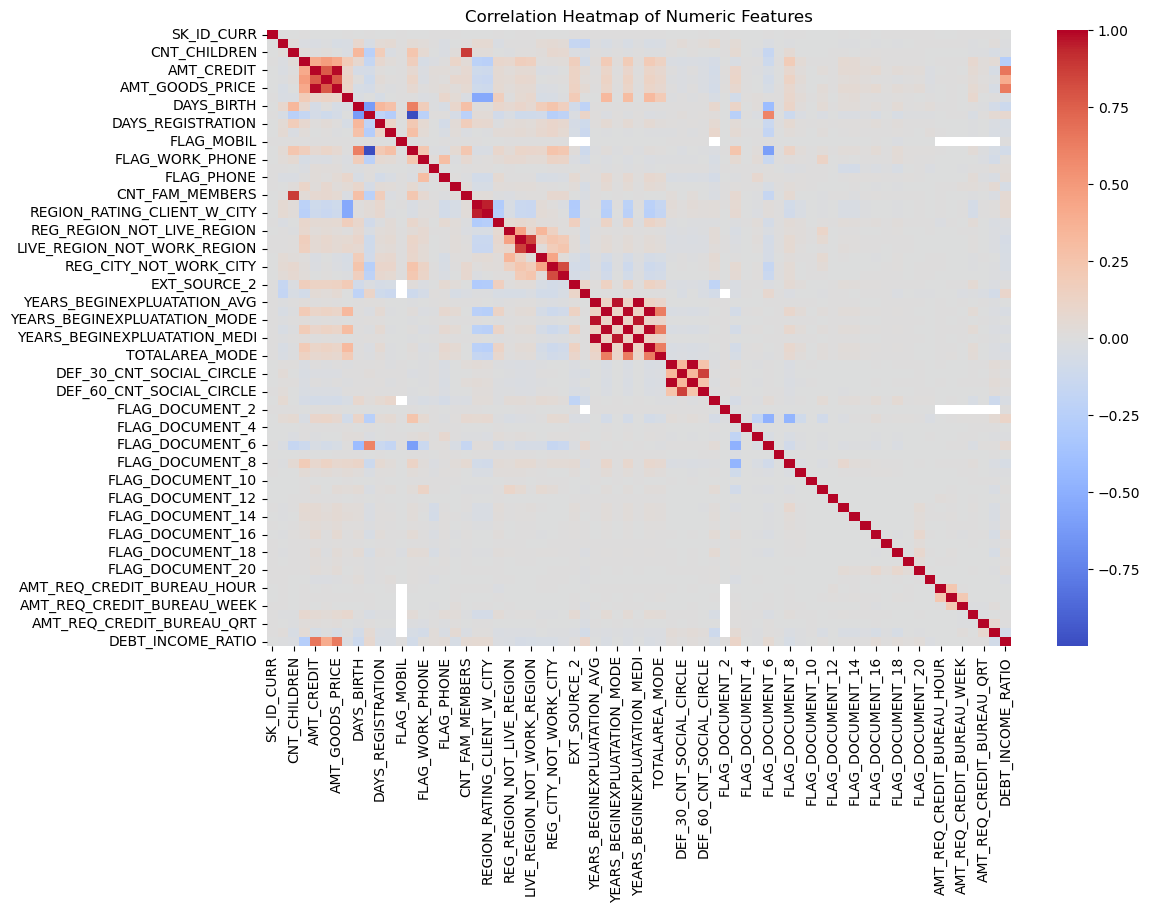

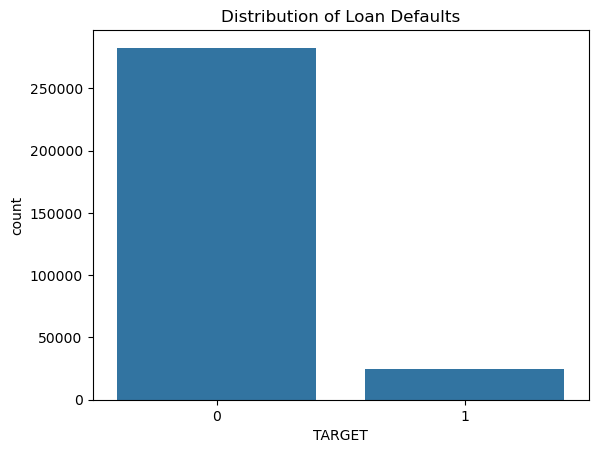

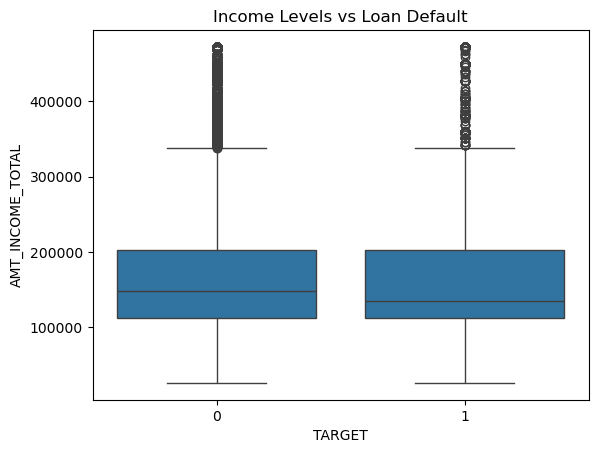

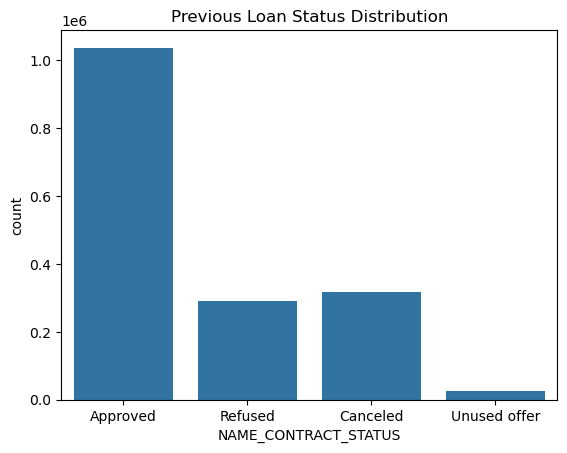

In [44]:
# Heatmap using only numeric columns
plt.figure(figsize=(12, 8))
numeric_cols = application_data_cleaned.select_dtypes(include=[np.number]).columns
sns.heatmap(application_data_cleaned[numeric_cols].corr(), annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

# Distribution of Target Variable (if available)
sns.countplot(data=application_data_cleaned, x='TARGET')
plt.title('Distribution of Loan Defaults')
plt.show()

# Income levels by default status
sns.boxplot(data=application_data_cleaned, x='TARGET', y='AMT_INCOME_TOTAL')
plt.title('Income Levels vs Loan Default')
plt.show()

# Loan status distribution in previous applications
sns.countplot(data=previous_application_cleaned, x='NAME_CONTRACT_STATUS')
plt.title('Previous Loan Status Distribution')
plt.show()


In [46]:
# Add descriptions to the EDA summary
eda_summary = application_data_cleaned.describe().transpose()
eda_summary['Description'] = eda_summary.index.map(column_descriptions.get)
print(eda_summary)


                               count           mean            std  \
SK_ID_CURR                  307511.0  278180.518577  102790.175348   
TARGET                      307511.0       0.080729       0.272419   
CNT_CHILDREN                307511.0       0.417052       0.722121   
AMT_INCOME_TOTAL            307511.0  166025.922341   83063.469251   
AMT_CREDIT                  307511.0  599025.999706  402490.776996   
...                              ...            ...            ...   
AMT_REQ_CREDIT_BUREAU_WEEK  265992.0       0.034362       0.204685   
AMT_REQ_CREDIT_BUREAU_MON   265992.0       0.267395       0.916002   
AMT_REQ_CREDIT_BUREAU_QRT   265992.0       0.265474       0.794056   
AMT_REQ_CREDIT_BUREAU_YEAR  265992.0       1.899974       1.869295   
DEBT_INCOME_RATIO           307511.0       3.963758       2.686391   

                                      min            25%            50%  \
SK_ID_CURR                  100002.000000  189145.500000  278202.000000   
TARGET   

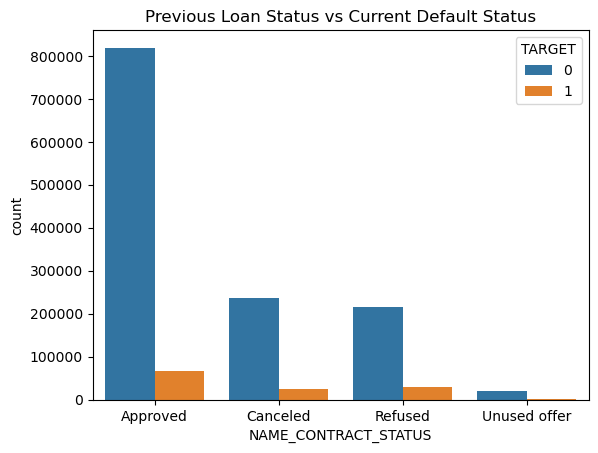

In [48]:
# Merge current and previous loan data
merged_data = pd.merge(application_data_cleaned, previous_application_cleaned, on='SK_ID_CURR', how='left')

# Analyze the relationship between current loan status and previous loan approvals
sns.countplot(data=merged_data, x='NAME_CONTRACT_STATUS', hue='TARGET')
plt.title('Previous Loan Status vs Current Default Status')
plt.show()
